# Training with Self-Consistency

This notebook shows how to train an estimator with a self-consistency (SC) loss. 

Standard amortized Bayesian inference (ABI) trains a posterior estimator on simulated parameter-observation pairs. After training, the posterior estimator can be evaluated on empirical data for inference to obtain samples from the posterior distribution of the parameters. When the empirical data lie outside of the training distribution, there are no guarantees for the posterior estimator.

The self-consistency loss addresses this by enforcing constraints implied by Bayes' theorem. For any fixed observation $y$, the quantity
$$\log p(\theta) + \log p(y \mid \theta) - \log q(\theta \mid y)$$
equals the log marginal likelihood $\log p(y)$, which does not depend on $\theta$. This means that if the posterior estimator $q(\theta \mid y)$ is correct, the above expression must be constant across different parameter values $\theta$. The SC loss minimizes the variance of this quantity across posterior samples, pushing the estimator toward a posterior distribution that is consistent with the prior and likelihood.

The SC loss requires only a dataset of observables without parameter labels, making it an unsupervised loss. We use the semi-supervised estimator to combine the SC loss with standard simulation-based losses that rely on simulated observation-parameter pairs. 

For more details about SC, please see [Schmitt et al. (2024)](https://proceedings.mlr.press/v235/schmitt24a.html) and [Mishra et al. (2025)](https://arxiv.org/abs/2501.13483).

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import keras
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import bayesflow as bf
import torch

import bayesflow.experimental.self_consistency as sc

INFO:bayesflow:Using backend 'torch'


When using torch backend, we need to disable autograd by default to avoid excessive memory usage. Use

with torch.enable_grad():
    ...

in contexts where you need gradients (e.g. custom training loops).


## Model

We use a Normal model with a Normal-Gamma prior (mean-precision parameterization):

$$\tau \sim \text{Gamma}(2, 1), \quad \mu \mid \tau \sim \mathcal{N}(0,\, \tau^{-1}), \quad y_i \mid \mu, \tau \sim \mathcal{N}(\mu,\, \tau^{-1})$$

The Normal-Gamma prior is conjugate to the normal likelihood, so the true posterior is available analytically (which we will use for validation).

In [2]:
def sim_fn():
    tau = np.random.gamma(size=1, shape=2, scale=1)
    mu = np.random.normal(size=1, scale=1.0 / np.sqrt(tau))
    y = np.random.normal(size=10, loc=mu, scale=1.0 / np.sqrt(tau))
    return dict(mu=mu, tau=tau, y=y)

simulator = bf.make_simulator(sim_fn)

Precision $\tau$ is strictly positive, so we map it to unconstrained network space with a numerically stable softplus constraint.

In [3]:
adapter = bf.Adapter().constrain("tau", lower=0, inclusive="none")

## Datasets

Here we have two datasets:

- **labeled**: simulated data with known parameters `(mu, tau)` and the observations `y` — used for standard posterior training.
- **unlabeled**: empirical observations `y` only, drawn from any generating model. Since no true parameter values are required, these may be real-world data as well. Here, the unlabeled data are simulated and set to have high variance (low precision). Therefore, we know they are out-of-distribution with respect to the assumed model.

In principle, the `SemiSupervisedEstimator` can be trained on any number of datasets. This allows, for example, separate supervised training of a posterior and likelihood network (when the likelihood is not analytic).

In [4]:
dataset_labeled = bf.OnlineDataset(
    simulator=simulator,
    adapter=adapter,
    batch_size=64, 
    num_batches=50
)

The unlabeled dataset does not contain the parameters, and the adapter only transforms parameters. Therefore, the adapter for the unlabeled dataset can remain empty.

In [5]:
dataset_unlabeled = bf.OfflineDataset(
    data=dict(y=np.random.normal(loc=0.0, scale=10, size=(32, 10))),
    adapter=bf.Adapter(),
    batch_size=8
)

We wrap all datasets used for training into one dataset class. Each batch is a dictionary containing batches from the individual datasets.

In [6]:
dataset = sc.MultiDataset(labeled=dataset_labeled, unlabeled=dataset_unlabeled)

print(dataset[0].keys())
print(dataset[0]["labeled"].keys())
print(dataset[0]["unlabeled"].keys())

dict_keys(['labeled', 'unlabeled'])
dict_keys(['mu', 'tau', 'y'])
dict_keys(['y'])


## Prior and likelihood

The SC loss needs access to the prior and likelihood log-densities.

Here we define the prior and likelihood analytically. Alternatively, they may also be approximated.

These functions receive parameters in the **original** (untransformed) space, so you do not need to map $\tau$ back from the unconstrained space manually. Log-density evaluation is not batched automatically, so the functions handle the batch dimensions explicitly. We use differentiable PyTorch distributions so that the log-probabilities can be evaluated during training.

In [7]:
def prior_log_prob(mu, tau, **kwargs):
    tau_log_prob = torch.distributions.Gamma(
        concentration=torch.full_like(tau, 2.0), rate=torch.ones_like(tau)
    ).log_prob(tau)
    mu_log_prob = torch.distributions.Normal(loc=0.0, scale=torch.rsqrt(tau)).log_prob(mu)
    return mu_log_prob + tau_log_prob

In [8]:
def likelihood_log_prob(y, mu, tau, **kwargs):
    y_log_prob = torch.distributions.Normal(loc=mu, scale=torch.rsqrt(tau)).log_prob(y)
    return torch.sum(y_log_prob, dim=1)

## Posterior estimator

We use a `BasicEstimator` with a `CouplingFlow` inference network and a `DeepSet` summary network. We also specify an adapter for the estimator itself. This local adapter runs after the global adapter that transforms `tau`. The global adapter handles operations shared by all estimators, whereas local adapters reshape data for a specific estimator. Here, the local adapter marks `mu` and `tau` as inference variables and `y` as summary variables, thereby defining a posterior estimator.

In [9]:
posterior_adapter = (
    bf.Adapter()
    .as_set("y")
    .concatenate(["mu", "tau"], into="inference_variables")
    .rename("y", "summary_variables")
)

In [10]:
posterior = bf.BasicEstimator(
    inference_network=bf.networks.CouplingFlow(),
    summary_network=bf.networks.DeepSet(),
    adapter=posterior_adapter
)

The main estimator wraps all components in one object. Here, the prior and likelihood are analytic, while the posterior is approximated.

In [11]:
estimator = sc.SemiSupervisedEstimator(
    estimators={
        "prior": prior_log_prob,
        "likelihood": likelihood_log_prob,
        "posterior": posterior,
    },
    adapter=adapter,
)

Before training, we also generate synthetic data for evaluation. These observations have high variance (low precision), so they are out-of-distribution with respect to the simulator but not with respect to the unlabeled data.

In [12]:
eval_data = dict(y=np.random.normal(loc=0.0, scale=10, size=(1, 10)))
samples = dict()

## Phase 1: Supervised training only

First, we train the posterior on labeled (simulated) data only. We do this through the estimator-specific metrics, specifying which estimator (here, `posterior`) should train on which dataset (here, `labeled`).

In [13]:
schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=1e-3, decay_steps=100 * dataset.num_batches
)
optimizer = keras.optimizers.AdamW(schedule, clipvalue=1.0)

estimator.compile(
    optimizer,
    estimator_metrics={"labeled": ["posterior"]}
)

history = estimator.fit(dataset=dataset, epochs=10, verbose=2)

INFO:bayesflow:Fitting on dataset instance of MultiDataset.


INFO:bayesflow:Building on a test batch.


Epoch 1/10


50/50 - 2s - 46ms/step - labeled/posterior/loss: 2.1888 - loss: 2.1888


Epoch 2/10


...

50/50 - 2s - 41ms/step - labeled/posterior/loss: 0.8599 - loss: 0.8599


Epoch 9/10


50/50 - 2s - 41ms/step - labeled/posterior/loss: 0.9394 - loss: 0.9394


Epoch 10/10


50/50 - 2s - 41ms/step - labeled/posterior/loss: 0.9172 - loss: 0.9172


In [14]:
samples["No SC"] = estimator.sample(estimator="posterior", num_samples=1000, conditions=eval_data)

## Phase 2: Self-consistency training

Next, we add the SC loss on unlabeled data and continue training. Bayes' theorem gives

$$\log p(y) = \log p(\mu, \tau) + \log p(y \mid \mu, \tau) - \log q(\mu, \tau \mid y)$$

This quantity should have zero variance across parameter samples, which drives the posterior toward consistency with the prior and likelihood.

We add the SC loss as a composite metric (a metric that combines multiple estimators) on the `unlabeled` dataset.

In [15]:
estimator.compile(
    optimizer,
    estimator_metrics={"labeled": ["posterior"]},
    composite_metrics={
        "unlabeled": sc.SelfConsistencyLoss(num_samples=16)
    }
)

history = estimator.fit(dataset=dataset, epochs=10, verbose=2)

INFO:bayesflow:Fitting on dataset instance of MultiDataset.


Epoch 1/10


50/50 - 5s - 102ms/step - labeled/posterior/loss: 1.5897 - loss: 8.9078 - unlabeled/self-consistency/loss: 7.3181


Epoch 2/10


50/50 - 5s - 101ms/step - labeled/posterior/loss: 1.0086 - loss: 2.0605 - unlabeled/self-consistency/loss: 1.0520


...

50/50 - 5s - 104ms/step - labeled/posterior/loss: 0.8675 - loss: 1.1312 - unlabeled/self-consistency/loss: 0.2637


Epoch 9/10


50/50 - 5s - 102ms/step - labeled/posterior/loss: 0.8030 - loss: 0.9602 - unlabeled/self-consistency/loss: 0.1572


Epoch 10/10


50/50 - 5s - 102ms/step - labeled/posterior/loss: 0.8487 - loss: 0.9481 - unlabeled/self-consistency/loss: 0.0994


In [16]:
samples["SC"] = estimator.sample(estimator="posterior", num_samples=1000, conditions=eval_data)

## Evaluation

Now we compare the results from simulation-based training and self-consistency training.

The Normal-Gamma posterior is available in closed form, so we compare posterior samples from both training methods with samples from this reference.

In [17]:
def sample_posterior(y, n_samples, mu0=0.0, kappa=1.0, shape=2.0, scale=1.0):
    y = y.flatten()
    n = len(y)
    ybar = np.mean(y)
    S = np.sum((y - ybar) ** 2)

    kappa_n = kappa + n
    mu_n = (kappa * mu0 + n * ybar) / kappa_n
    shape_n = shape + n / 2
    rate_n = 1 / scale + 0.5 * S + (kappa * n / (2 * kappa_n)) * (ybar - mu0) ** 2

    tau = np.random.gamma(shape=shape_n, scale=1.0 / rate_n, size=n_samples)
    mu = np.random.normal(loc=mu_n, scale=1.0 / np.sqrt(kappa_n * tau), size=n_samples)

    return dict(mu=mu, tau=tau)


samples["Reference"] = sample_posterior(eval_data["y"], n_samples=1000)

Samples from the estimator trained with the SC loss are much more similar to the reference than pure simulation-based training.

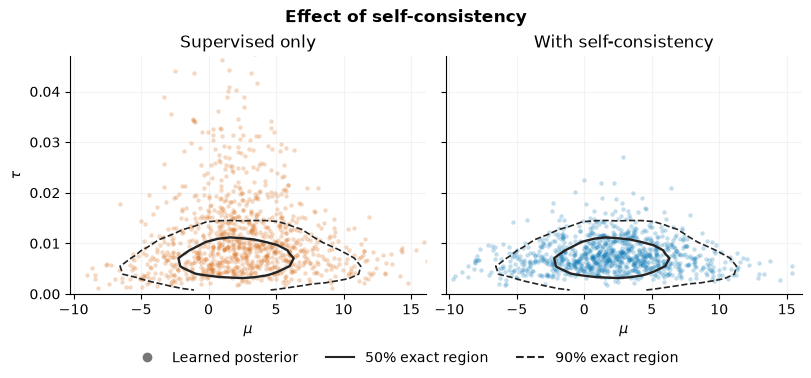

In [ ]:
COLORS = {
    "No SC": "#D55E00",
    "SC": "#0072B2",
    "SC, approximate likelihood": "#009E73",
}
LABELS = {
    "No SC": "Supervised only",
    "SC": "With self-consistency",
    "SC, approximate likelihood": "SC + learned likelihood",
}


def plot_posteriors(samples, methods, *, title):
    ref_mu = np.asarray(samples["Reference"]["mu"]).ravel()
    ref_tau = np.asarray(samples["Reference"]["tau"]).ravel()
    values = [samples[name] for name in methods] + [samples["Reference"]]

    def limits(key, lower=None):
        x = np.concatenate([np.asarray(value[key]).ravel() for value in values])
        lo, hi = np.quantile(x[np.isfinite(x)], [0.005, 0.995])
        pad = 0.08 * max(hi - lo, 1e-6)
        return (max(lower, lo - pad) if lower is not None else lo - pad, hi + pad)

    mu_lim, tau_lim = limits("mu"), limits("tau", lower=0.0)
    density, mu_edges, tau_edges = np.histogram2d(
        ref_mu, ref_tau, bins=30, range=[mu_lim, tau_lim]
    )
    # Light smoothing keeps finite-sample reference contours readable.
    for _ in range(2):
        padded = np.pad(density, 1, mode="edge")
        density = sum(
            padded[i : i + density.shape[0], j : j + density.shape[1]]
            for i in range(3)
            for j in range(3)
        ) / 9
    ranked = np.sort(density.ravel())[::-1]
    mass = np.cumsum(ranked) / ranked.sum()
    levels = np.unique(
        np.sort([ranked[np.searchsorted(mass, probability)] for probability in (0.90, 0.50)])
    )
    mu_centers = (mu_edges[:-1] + mu_edges[1:]) / 2
    tau_centers = (tau_edges[:-1] + tau_edges[1:]) / 2

    with plt.rc_context({"axes.spines.top": False, "axes.spines.right": False}):
        fig, axes = plt.subplots(
            1, 2, figsize=(8.0, 3.7), sharex=True, sharey=True, constrained_layout=True, squeeze=False)

        for ax, name in zip(axes[0], methods):
            mu = np.asarray(samples[name]["mu"]).ravel()
            tau = np.asarray(samples[name]["tau"]).ravel()

            ax.scatter(mu, tau, s=10, alpha=0.24, linewidth=0, color=COLORS[name], rasterized=True)
            ax.contour(mu_centers, tau_centers, density.T, levels=levels, colors="#242424",
                linestyles=["--", "-"][-len(levels) :],
                linewidths=[1.2, 1.7][-len(levels) :],
            )
            ax.set(xlim=mu_lim, ylim=tau_lim, xlabel=r"$\mu$", title=LABELS[name])
            ax.grid(alpha=0.15)
        axes[0, 0].set_ylabel(r"$\tau$")

        fig.suptitle(title, fontweight="bold")
        fig.legend(
            handles=[
                Line2D([], [], marker="o", linestyle="none", color="#777777", label="Learned posterior"),
                Line2D([], [], color="#242424", label="50% exact region"),
                Line2D([], [], color="#242424", linestyle="--", label="90% exact region"),
            ],
            loc="outside lower center",
            ncol=3,
            frameon=False,
        )
    return fig


plot_posteriors(samples, ["No SC", "SC"], title="Effect of self-consistency")

## Approximate posterior and likelihood

The prior and likelihood need not be analytic and may also be approximated. To do this, we specify multiple estimators that use different arguments as inference variables, summary variables, and inference conditions.

Here is how to approximate both the posterior and likelihood (NPLE) and train them with self-consistency.

First, we define the posterior estimator as above.

In [19]:
posterior_adapter=(
    bf.Adapter()
    .as_set("y")
    .concatenate(["mu", "tau"], into="inference_variables")
    .rename("y", "summary_variables")
)

In [20]:
posterior_estimator = bf.BasicEstimator(
    inference_network = bf.networks.CouplingFlow(),
    summary_network = bf.networks.DeepSet(),
    adapter = posterior_adapter,
)

Then, we define a likelihood estimator. This estimator predicts the distribution of data `y` given parameters `mu` and `tau`. Therefore, the likelihood adapter uses `mu` and `tau` as inference conditions and `y` as inference variables.

In [21]:
likelihood_adapter = (
    bf.Adapter()
    .concatenate(["mu", "tau"], into="inference_conditions")
    .rename("y", "inference_variables")
)

In [22]:
likelihood_estimator = bf.BasicEstimator(
    inference_network = bf.networks.CouplingFlow(),
    summary_network = None,
    adapter = likelihood_adapter,
)

In [23]:
estimator_nple = sc.SemiSupervisedEstimator(
    estimators = {
        "prior": prior_log_prob,
        "likelihood": likelihood_estimator,
        "posterior": posterior_estimator
    },
    adapter=adapter
)

Typically, it is a good idea to pretrain the networks with pure simulation-based training. We specify that both posterior and likelihood estimators should train with their own metrics evaluated on the labeled dataset.

In [24]:
estimator_nple.compile(
    optimizer=keras.optimizers.AdamW(schedule, clipvalue=1.0),
    estimator_metrics={"labeled": ["posterior", "likelihood"]}
)

history = estimator_nple.fit(dataset=dataset, epochs=10, verbose=2)

INFO:bayesflow:Fitting on dataset instance of MultiDataset.


INFO:bayesflow:Building on a test batch.


Epoch 1/10


50/50 - 3s - 69ms/step - labeled/likelihood/loss: 10.5046 - labeled/posterior/loss: 2.1947 - loss: 12.6993


Epoch 2/10


...

50/50 - 3s - 70ms/step - labeled/likelihood/loss: 8.7915 - labeled/posterior/loss: 0.9663 - loss: 9.7578


Epoch 9/10


50/50 - 3s - 70ms/step - labeled/likelihood/loss: 8.7982 - labeled/posterior/loss: 0.9036 - loss: 9.7017


Epoch 10/10


50/50 - 3s - 69ms/step - labeled/likelihood/loss: 8.8489 - labeled/posterior/loss: 0.8856 - loss: 9.7345


After that, we can do SC training. Note that by default, only the posterior network is trained with self-consistency. You can change that using the argument `gradient` in `sc.SelfConsistencyLoss`.

In [25]:
estimator_nple.compile(
  keras.optimizers.AdamW(schedule, clipvalue=1.0),
  estimator_metrics={"labeled": ["posterior", "likelihood"]},
  composite_metrics={
      "unlabeled": sc.SelfConsistencyLoss(num_samples=16)
  }
)

history = estimator_nple.fit(dataset=dataset, epochs=10, verbose=2)

INFO:bayesflow:Fitting on dataset instance of MultiDataset.


Epoch 1/10


50/50 - 8s - 150ms/step - labeled/likelihood/loss: 8.7997 - labeled/posterior/loss: 1.0507 - loss: 17.2083 - unlabeled/self-consistency/loss: 7.3579


Epoch 2/10


50/50 - 7s - 149ms/step - labeled/likelihood/loss: 8.7824 - labeled/posterior/loss: 1.0131 - loss: 10.9982 - unlabeled/self-consistency/loss: 1.2027


...

50/50 - 8s - 150ms/step - labeled/likelihood/loss: 8.8721 - labeled/posterior/loss: 0.8775 - loss: 11.0189 - unlabeled/self-consistency/loss: 1.2693


Epoch 9/10


50/50 - 8s - 150ms/step - labeled/likelihood/loss: 8.8106 - labeled/posterior/loss: 0.9283 - loss: 10.9105 - unlabeled/self-consistency/loss: 1.1716


Epoch 10/10


50/50 - 8s - 150ms/step - labeled/likelihood/loss: 8.5781 - labeled/posterior/loss: 0.9419 - loss: 10.7781 - unlabeled/self-consistency/loss: 1.2581


In [ ]:
samples["SC, approximate likelihood"] = estimator_nple.sample(
    estimator="posterior", 
    num_samples=1000, 
    conditions=eval_data
)

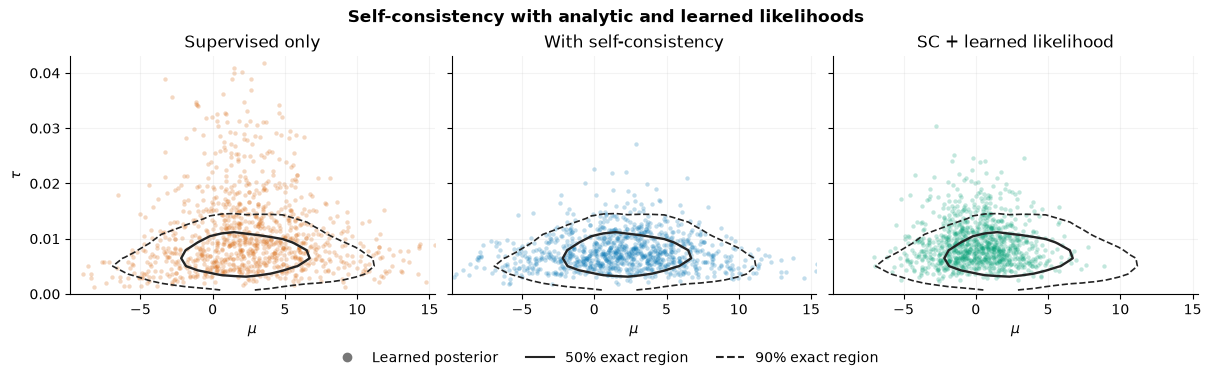

In [ ]:
plot_posteriors(
    samples,
    ["No SC", "SC", "SC, approximate likelihood"],
    title="Self-consistency with analytic and learned likelihoods",
)